<a href="https://colab.research.google.com/github/SashaVeremchuk/Gazprom-production-forecast/blob/main/one_well.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Работа с одной скважиной `15/9-F-14`.

In [42]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Загрузка данных

In [43]:
url = "https://raw.githubusercontent.com/SashaVeremchuk/Gazprom-production-forecast/refs/heads/main/one_well.csv"
df = pd.read_csv(url)
print(df.head())


      DATEPRD NPD_WELL_BORE_NAME  ON_STREAM_HRS  AVG_DOWNHOLE_PRESSURE  AVG_DP_TUBING  AVG_ANNULUS_PRESS  AVG_CHOKE_SIZE_P  AVG_WHP_P  AVG_WHT_P  BORE_OIL_VOL  BORE_GAS_VOL  BORE_WAT_VOL WELL_TYPE
0  2008-02-12          15/9-F-14           0.00                   0.00           0.00               0.00              0.67       0.00       0.00          0.00          0.00          0.00        OP
1  2008-02-13          15/9-F-14           0.00                   0.00           0.00               0.00              0.67       0.00       0.00          0.00          0.00          0.00        OP
2  2008-02-14          15/9-F-14           0.00                   0.00           0.00               0.00              0.67       0.00       0.00          0.00          0.00          0.00        OP
3  2008-02-15          15/9-F-14           0.00                   0.00           0.00               0.00              0.67       0.00       0.00          0.00          0.00          0.00        OP
4  2008-02-16  

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3056 entries, 0 to 3055
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   DATEPRD                3056 non-null   object 
 1   NPD_WELL_BORE_NAME     3056 non-null   object 
 2   ON_STREAM_HRS          3056 non-null   float64
 3   AVG_DOWNHOLE_PRESSURE  3056 non-null   float64
 4   AVG_DP_TUBING          3056 non-null   float64
 5   AVG_ANNULUS_PRESS      3056 non-null   float64
 6   AVG_CHOKE_SIZE_P       3056 non-null   float64
 7   AVG_WHP_P              3056 non-null   float64
 8   AVG_WHT_P              3056 non-null   float64
 9   BORE_OIL_VOL           3056 non-null   float64
 10  BORE_GAS_VOL           3056 non-null   float64
 11  BORE_WAT_VOL           3056 non-null   float64
 12  WELL_TYPE              3056 non-null   object 
dtypes: float64(10), object(3)
memory usage: 310.5+ KB


## Подготовка данных для дальнейшей работы
1. Удаляем текстовые константы
2. Исключаем дни полного простоя скважины
3. Формируем месячный ряд только по существующим колонкам

In [45]:
import pandas as pd

# 1. Переносим DATEPRD в индекс только если она еще среди колонок
if "DATEPRD" in df.columns:
    df["DATEPRD"] = pd.to_datetime(df["DATEPRD"])
    df = df.sort_values("DATEPRD").set_index("DATEPRD")
else:
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()

# 2. Удаляем текстовые константы
df = df.drop(columns=["NPD_WELL_BORE_NAME", "WELL_TYPE"], errors="ignore")

# 3. Исключаем дни полного простоя скважины
df_daily = df[df["ON_STREAM_HRS"] > 0].copy()

# 4. Формируем месячный ряд только по существующим колонкам
sum_cols = ["ON_STREAM_HRS", "BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL"]
mean_cols = [
    "AVG_DOWNHOLE_PRESSURE",
    "AVG_DP_TUBING",
    "AVG_ANNULUS_PRESS",
    "AVG_CHOKE_SIZE_P",
    "AVG_WHP_P",
    "AVG_WHT_P",
]

agg_rules = {c: "sum" for c in sum_cols if c in df_daily.columns}
agg_rules.update({c: "mean" for c in mean_cols if c in df_daily.columns})

df_monthly = df_daily.resample("MS").agg(agg_rules).dropna()

print(f"Суточных записей: {len(df_daily)}")
print(f"Месячных записей: {len(df_monthly)}")

Суточных записей: 2724
Месячных записей: 97


In [46]:
df_daily.head()

,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,AVG_DP_TUBING,AVG_ANNULUS_PRESS,AVG_CHOKE_SIZE_P,AVG_WHP_P,AVG_WHT_P,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL
DATEPRD,,,,,,,,,,
2008-07-13,24.00,260.87,160.15,0.00,21.05,100.71,52.38,"1,735.26","252,235.23",4.00
2008-07-14,5.57,256.25,156.65,0.00,27.22,99.60,71.12,592.36,"88,949.00",1.37
2008-07-15,24.00,254.98,156.33,0.00,27.28,98.65,67.59,"2,532.21","373,786.28",5.84
2008-07-16,24.00,251.48,155.82,0.00,30.65,95.66,73.78,"3,030.71","447,840.09",9.13
2008-07-17,24.00,249.35,155.76,0.00,32.56,93.59,78.04,"3,288.08","474,614.43",7.58


## Анализ данных
1. Визуализация кривой падения добычи
2. Декомпозиция временного ряда: тренд, сезонность, остатки
3. Тест Дики-Фуллера на стационарность


### Визуализация кривой падения добычи (суточная и месячная)

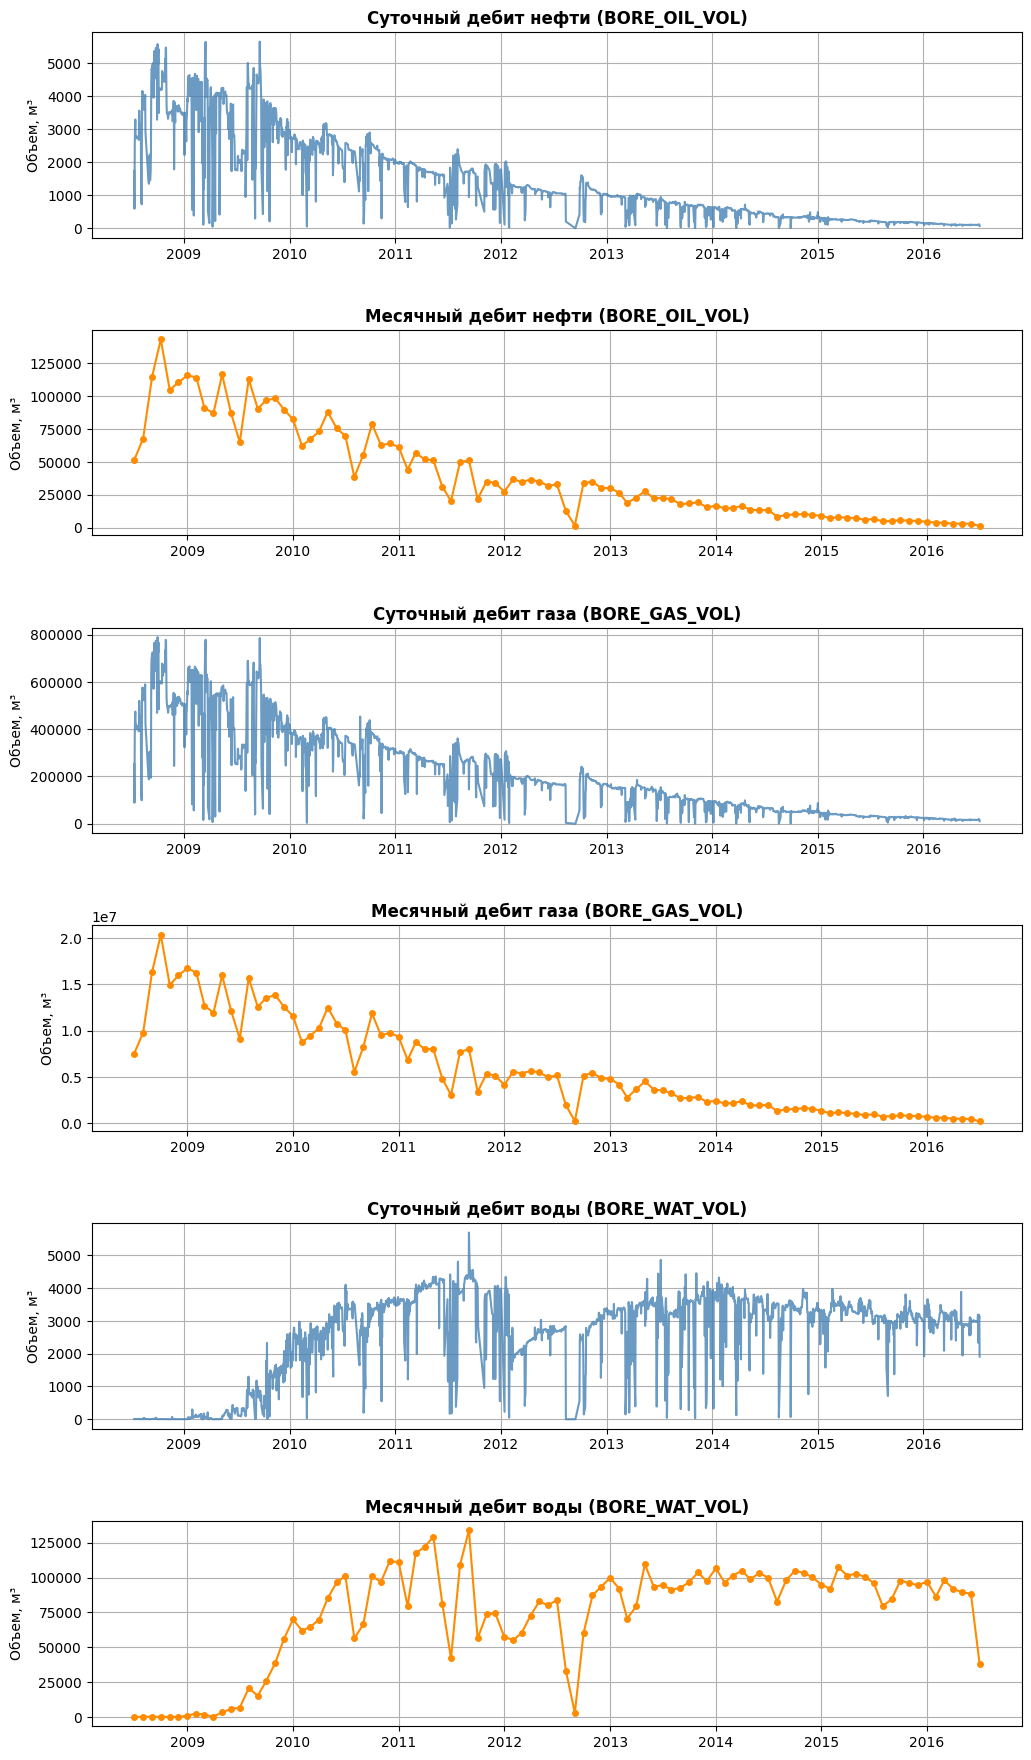

In [47]:
fig, axes = plt.subplots(6, 1, figsize=(12, 22))

axes[0].plot(df_daily.index, df_daily["BORE_OIL_VOL"], color="steelblue", alpha=0.8)
axes[0].set_title("Суточный дебит нефти (BORE_OIL_VOL)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Объем, м³")
axes[0].grid(True)

axes[1].plot(df_monthly.index, df_monthly["BORE_OIL_VOL"], color="darkorange", marker="o", markersize=4)
axes[1].set_title("Месячный дебит нефти (BORE_OIL_VOL)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Объем, м³")
axes[1].grid(True)

axes[2].plot(df_daily.index, df_daily["BORE_GAS_VOL"], color="steelblue", alpha=0.8)
axes[2].set_title("Суточный дебит газа (BORE_GAS_VOL)", fontsize=12, fontweight="bold")
axes[2].set_ylabel("Объем, м³")
axes[2].grid(True)

axes[3].plot(df_monthly.index, df_monthly["BORE_GAS_VOL"], color="darkorange", marker="o", markersize=4)
axes[3].set_title("Месячный дебит газа (BORE_GAS_VOL)", fontsize=12, fontweight="bold")
axes[3].set_ylabel("Объем, м³")
axes[3].grid(True)

axes[4].plot(df_daily.index, df_daily["BORE_WAT_VOL"], color="steelblue", alpha=0.8)
axes[4].set_title("Суточный дебит воды (BORE_WAT_VOL)", fontsize=12, fontweight="bold")
axes[4].set_ylabel("Объем, м³")
axes[4].grid(True)

axes[5].plot(df_monthly.index, df_monthly["BORE_WAT_VOL"], color="darkorange", marker="o", markersize=4)
axes[5].set_title("Месячный дебит воды (BORE_WAT_VOL)", fontsize=12, fontweight="bold")
axes[5].set_ylabel("Объем, м³")
axes[5].grid(True)

plt.subplots_adjust(hspace=0.45)
plt.show()

### Декомпозиция временного ряда: тренд, сезонность, остатки
Смотрим на годовой цикл

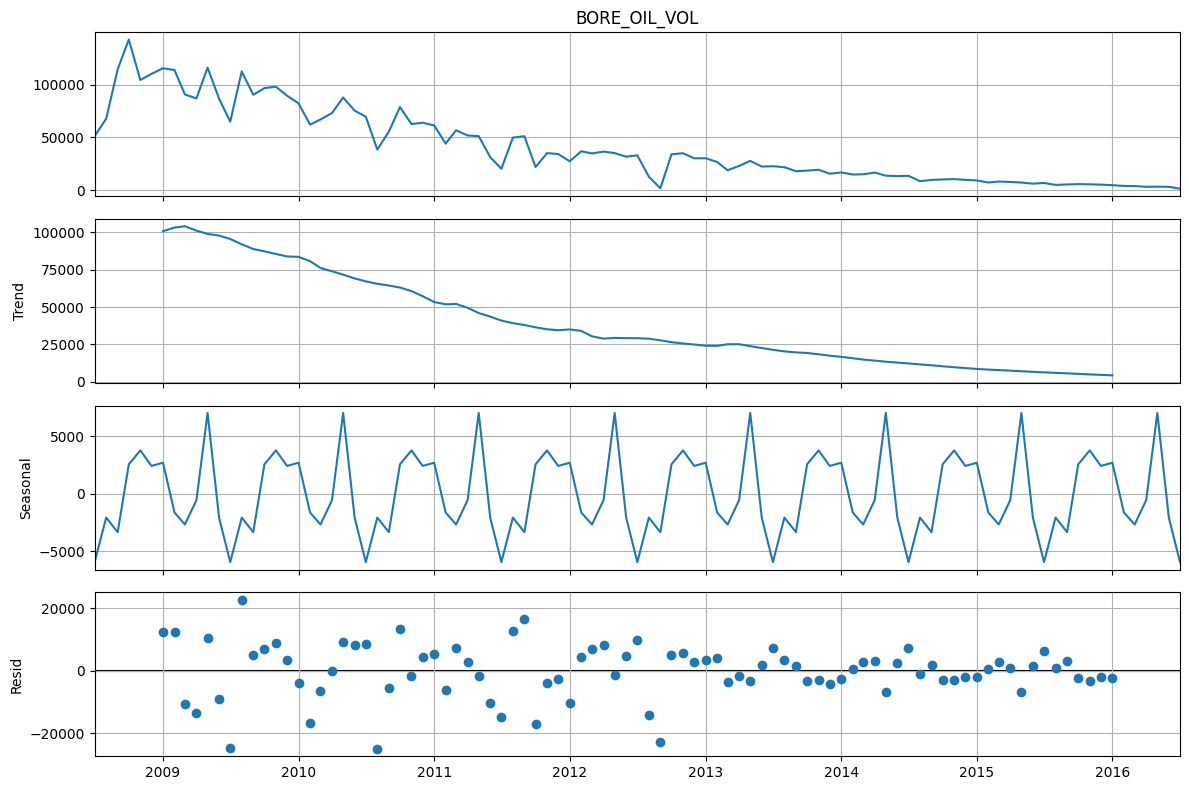

In [48]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Используем period=12, так как данные помесячные (годовой цикл)
decomposition = seasonal_decompose(df_monthly["BORE_OIL_VOL"], model="additive", period=12)
fig_decomp = decomposition.plot()
fig_decomp.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

**Тренд (Trend):** Показывает чистое, сглаженное направление изменения добычи без случайных скачков. Линия уверенно идет вниз (с 100 000 до менее 10 000 м³) - это классическая кривая истощения пласта, которая доказывает нестационарность ряда.   

**Сезонность (Seasonal):** Выделяет строго повторяющиеся из года в год колебания в пределах ±5 000 м³. В нефтедобыче на морском шельфе (месторождение Volve) такая «сезонность» связана не с погодой, а с разным количеством дней в месяцах (например, провал в феврале) и ежегодным графиком плановых остановок на техническое обслуживание летом или осенью.   

**Остатки (Resid):** Показывает случайные отклонения и аномалии, которые не объясняются ни трендом, ни сезонностью. Обрати внимание на два важных свойства:
* **Резкие провалы вниз** (например, в середине 2009, 2010 и конце 2012 года) — это месяцы, когда скважина долго простаивала на ремонте, из-за чего суммарная добыча за месяц резко падала.
* **Затухание разброса** (гетероскедастичность): В 2009–2012 годах разброс точек достигает ±20 000 м³, а после 2013 года точки лежат плотно около нуля - амплитуда шума уменьшается пропорционально падению самого дебита.

**Выводы:**  
При построении ML-модели нужно учесть:  
* **Обязательны лаги и скользящие средние:** Из-за сильного нисходящего тренда модели нужны прошлые значения добычи (за 1, 3, 6 месяцев), чтобы понимать текущий уровень истощения скважины.
* **Нужен учет часов работы (ON_STREAM_HRS):** Резкие провалы в остатках вызваны неполными месяцами работы, поэтому признак отработанных часов за месяц сильно поможет модели не путать ремонт с падением пластового давления.
* **Полезны календарные признаки:** Номер месяца позволит модели уловить повторяющуюся сезонность.


### Тест Дики-Фуллера на стационарность
**Тест Дики-Фуллера (ADF-тест)** проверяет, меняются ли среднее значение и разброс временного ряда с течением времени, то есть является ли ряд стационарным.

**Стационарный ряд** - это временной ряд, статистические свойства которого (среднее значение, разброс и сила связи между соседними точками) не меняются со временем. У **нестационарного ряда** эти характеристики со временем сдвигаются, например, из-за устойчивого роста, падения или сезонности.


**Зачем он нужен:**   
Дает строгое обоснование для выбора признаков: Доказывает, что **обычное среднее по всей истории для прогноза не подойдет** (ведь добыча постоянно падает), поэтому для обучения ML-моделей **необходимо подавать на вход свежие лаги** (лаг - предыдущие значения) (за 1, 3, 6 месяцев) и скользящие средние.


* Нулевая гипотеза (H₀): Ряд нестационарен (среднее значение и разброс меняются со временем, есть тренд).
* Альтернативная гипотеза (H₁): Ряд стационарен (добыча колеблется вокруг одного постоянного уровня).


In [49]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(df_monthly["BORE_OIL_VOL"],  regression='ct')
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4f}")
print("Критические значения:")
for key, value in adf_result[4].items():
    print(f"   {key}: {value:.4f}")

if adf_result[1] <= 0.05:
    print("Вывод: Ряд стационарен (отвергаем нулевую гипотезу).")
else:
    print("Вывод: Ряд нестационарен (есть выраженный тренд падения дебита).")

ADF Statistic: -1.2543
p-value: 0.8988
Критические значения:
   1%: -4.0694
   5%: -3.4635
   10%: -3.1580
Вывод: Ряд нестационарен (есть выраженный тренд падения дебита).


/tmp/ipykernel_1220/1860377151.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df_monthly["BORE_OIL_VOL"],  regression='ct')


**Вывод:**  
Ряд несационарен (есть выраженный тренд падения дебита).

## Формирование лаговых признаков:
* дебит за 1, 3, 6 предыдущих месяцев;
* скользящее среднее.

### Feature engineering

1. Признаки истории добычи нефти (4 переменных)  
* `oil_lag_1` — объем добычи нефти за 1 предыдущий месяц.
* `oil_lag_3` — объем добычи нефти 3 месяца назад.
* `oil_lag_6` — объем добычи нефти 6 месяцев назад.
* `oil_roll_mean_3` — скользящее среднее добычи нефти за последние 3 месяца (рассчитано строго по прошлым значениям).

2. Физические и технологические признаки за прошлый месяц (6 переменных)
*  `oil_rate_lag_1` - эффективный суточный дебит нефти за прошлый месяц (в пересчете на 24 часа работы без учета простоев).
*  `gor_lag_1` — газовый фактор (отношение добытого газа к нефти) за прошлый месяц.
*  `wc_lag_1` — обводненность продукции (доля воды в общем объеме жидкости) за прошлый месяц.
*  `ON_STREAM_HRS_lag_1` — количество отработанных часов за прошлый месяц.
*  `AVG_DOWNHOLE_PRESSURE_lag_1` — среднее забойное давление за прошлый месяц.
*  `AVG_WHP_P_lag_1` — среднее устьевое давление за прошлый месяц.

3. Временные и календарные признаки (2 переменных)
* `month` — порядковый номер календарного месяца (от 1 до 12) для учета сезонности.
* `time_idx` — сквозной счетчик месяцев с начала работы скважины (0, 1, 2, ...), отражающий возраст скважины и общий тренд истощения.

In [50]:
data = df_monthly.copy()

# 1. Физические показатели (эффективный дебит, газовый фактор и обводненность)
data["oil_rate"] = (data["BORE_OIL_VOL"] * 24) / data["ON_STREAM_HRS"]
data["gas_rate"] = (data["BORE_GAS_VOL"] * 24) / data["ON_STREAM_HRS"]
data["water_rate"] = (data["BORE_WAT_VOL"] * 24) / data["ON_STREAM_HRS"]
data["gor"] = data["gas_rate"] / (data["oil_rate"] + 1e-6)
data["wc"] = data["water_rate"] / (data["water_rate"] + data["oil_rate"] + 1e-6)

# 2. Лаги целевой переменной (за 1, 3, 6 месяцев) и скользящее среднее
data["oil_lag_1"] = data["BORE_OIL_VOL"].shift(1)
data["oil_lag_3"] = data["BORE_OIL_VOL"].shift(3)
data["oil_lag_6"] = data["BORE_OIL_VOL"].shift(6)
data["oil_roll_mean_3"] = data["BORE_OIL_VOL"].shift(1).rolling(window=3).mean()

# 3. Лаги физических показателей и датчиков (только за прошлый месяц, чтобы не было утечки из будущего)
extra_cols = ["oil_rate", "gor", "wc", "ON_STREAM_HRS", "AVG_DOWNHOLE_PRESSURE", "AVG_WHP_P"]
for col in extra_cols:
    if col in data.columns:
        data[f"{col}_lag_1"] = data[col].shift(1)

# 4. Календарные признаки и возраст скважины
data["month"] = data.index.month
data["time_idx"] = range(len(data))

# Оставляем таргет и признаки прошлого, удаляем первые 6 строк с NaN
feature_cols = [c for c in data.columns if "lag" in c or "roll" in c or c in ["month", "time_idx"]]
data = data[["BORE_OIL_VOL"] + feature_cols].dropna()

## Разбивка на обучение и тест
Стандартизум данные при помощи `StandartScaller`.  
Центр распределения: среднее значение (mean) каждого признака становится строго равным 0, а стандартное отклонение (std) становится равно 1.

In [51]:
from sklearn.preprocessing import StandardScaler

# 1. Сначала разделяем на train и test по времени (последние 12 месяцев в тест)
test_months = 12
train = data.iloc[:-test_months]
test = data.iloc[-test_months:]

X_train = train.drop(columns=["BORE_OIL_VOL"])
y_train = train["BORE_OIL_VOL"]

X_test = test.drop(columns=["BORE_OIL_VOL"])
y_test = test["BORE_OIL_VOL"]

# 2. Только теперь стандартизуем признаки (целевую переменную y не трогаем)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train_scaled: {X_train_scaled.shape}, X_test_scaled: {X_test_scaled.shape}")

X_train_scaled: (79, 12), X_test_scaled: (12, 12)


**Выводs:**   
* **Пропорция выборок (87% / 13%):** Из 91 доступного месяца работы скважины 79 месяцев (около 6.5 лет) ушли в обучение, а ровно 12 месяцев (1 полный год) — в тестовую выборку для проверки прогноза.
* **Совпадение признаков (12 столбцов):** И в X_train_scaled, и в X_test_scaled ровно по 12 колонок, без пропусков и перекосов.


## Моделирование процесса
1.	Baseline: классическая экспоненциальная кривая Арпса — для сравнения.
2.	ML-модели
3.	Оценка по метрикам: MAE, RMSE, R² — сравнение с baseline.
